In [1]:
from google.colab import drive
drive.mount('/content/drive5')

Mounted at /content/drive5


In [2]:

from pathlib import Path

PROJECT = Path("/content/drive5/MyDrive/Ocular_Project")

assert PROJECT.exists(), f"Project folder not found: {PROJECT}"

print("Project:", PROJECT)
print("\nRelevant IITD result folders:")

for folder in [
    PROJECT / "results/IITD/notebook06_gan_augmentation",
    PROJECT / "results/IITD/notebook07_diffusion",
    PROJECT / "results/IITD/notebook08_quality_diversity",
    PROJECT / "results/IITD/notebook09_dataset_augmentation",
    PROJECT / "results/IITD/notebook10_recognition_augmented",
]:
    print(f"\n{folder.name}: {'FOUND' if folder.exists() else 'NOT FOUND'}")
    if folder.exists():
        for item in list(folder.iterdir())[:8]:
            print("  ", item.name)


Project: /content/drive5/MyDrive/Ocular_Project

Relevant IITD result folders:

notebook06_gan_augmentation: FOUND
   training_samples
   IITD_gan_training_history.csv
   IITD_gan_training_summary.json
   improved_128

notebook07_diffusion: FOUND
   training_samples
   IITD_diffusion_training_summary.json
   IITD_diffusion_training_history.csv
   IITD_DDPM_sample_metadata.json
   final_sampling_attempt

notebook08_quality_diversity: FOUND
   IITD_real_quality_summary.csv
   IITD_traditional_sample_quality_metrics.csv
   IITD_GAN_sample_quality_metrics.csv
   IITD_diffusion_sample_quality_metrics.csv
   IITD_quality_diversity_all_metrics.csv
   IITD_quality_diversity_summary.csv
   IITD_quality_diversity_summary.json
   IITD_comparison_brightness_mean.png

notebook09_dataset_augmentation: FOUND
   IITD_original_split_manifest.csv
   IITD_traditional_train_manifest.csv
   IITD_gan_manifest.csv
   IITD_diffusion_manifest.csv
   IITD_dataset_augmentation_summary.json

notebook10_recognitio

In [3]:

import json
import pandas as pd

QUALITY_DIR = PROJECT / "results/IITD/notebook08_quality_diversity"
GAN_DIR = PROJECT / "results/IITD/notebook06_gan_augmentation"
DIFFUSION_DIR = PROJECT / "results/IITD/notebook07_diffusion"
OUT_DIR = PROJECT / "results/IITD/notebook11_gan_vs_diffusion"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("QUALITY / DIVERSITY CSV FILES")
for path in sorted(QUALITY_DIR.glob("*.csv")):
    print(f"\n--- {path.name} ---")
    df = pd.read_csv(path)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))

print("\n\nTRAINING SUMMARIES")
for path in [
    GAN_DIR / "IITD_gan_training_summary.json",
    DIFFUSION_DIR / "IITD_diffusion_training_summary.json",
    QUALITY_DIR / "IITD_quality_diversity_summary.json",
]:
    print(f"\n--- {path.name} ---")
    if path.exists():
        with open(path, "r") as f:
            print(json.dumps(json.load(f), indent=2)[:7000])
    else:
        print("File not found")


QUALITY / DIVERSITY CSV FILES

--- IITD_GAN_sample_quality_metrics.csv ---
Shape: (100, 5)
Columns: ['brightness_mean', 'contrast_std', 'sharpness_laplacian_variance', 'noise_proxy', 'source']
 brightness_mean  contrast_std  sharpness_laplacian_variance  noise_proxy     source
      142.459229     50.965858                   2135.815430     6.645215 gan_sample
      120.373291     56.000385                   2706.752930     7.187500 gan_sample
      137.759521     64.147049                   3354.147461     7.766992 gan_sample

--- IITD_diffusion_sample_quality_metrics.csv ---
Shape: (16, 5)
Columns: ['brightness_mean', 'contrast_std', 'sharpness_laplacian_variance', 'noise_proxy', 'source']
 brightness_mean  contrast_std  sharpness_laplacian_variance  noise_proxy               source
      123.420410     23.441084                   1811.447266     5.086426 diffusion_16_samples
      113.234131     19.532478                   1275.349121     4.328222 diffusion_16_samples
      120.1677

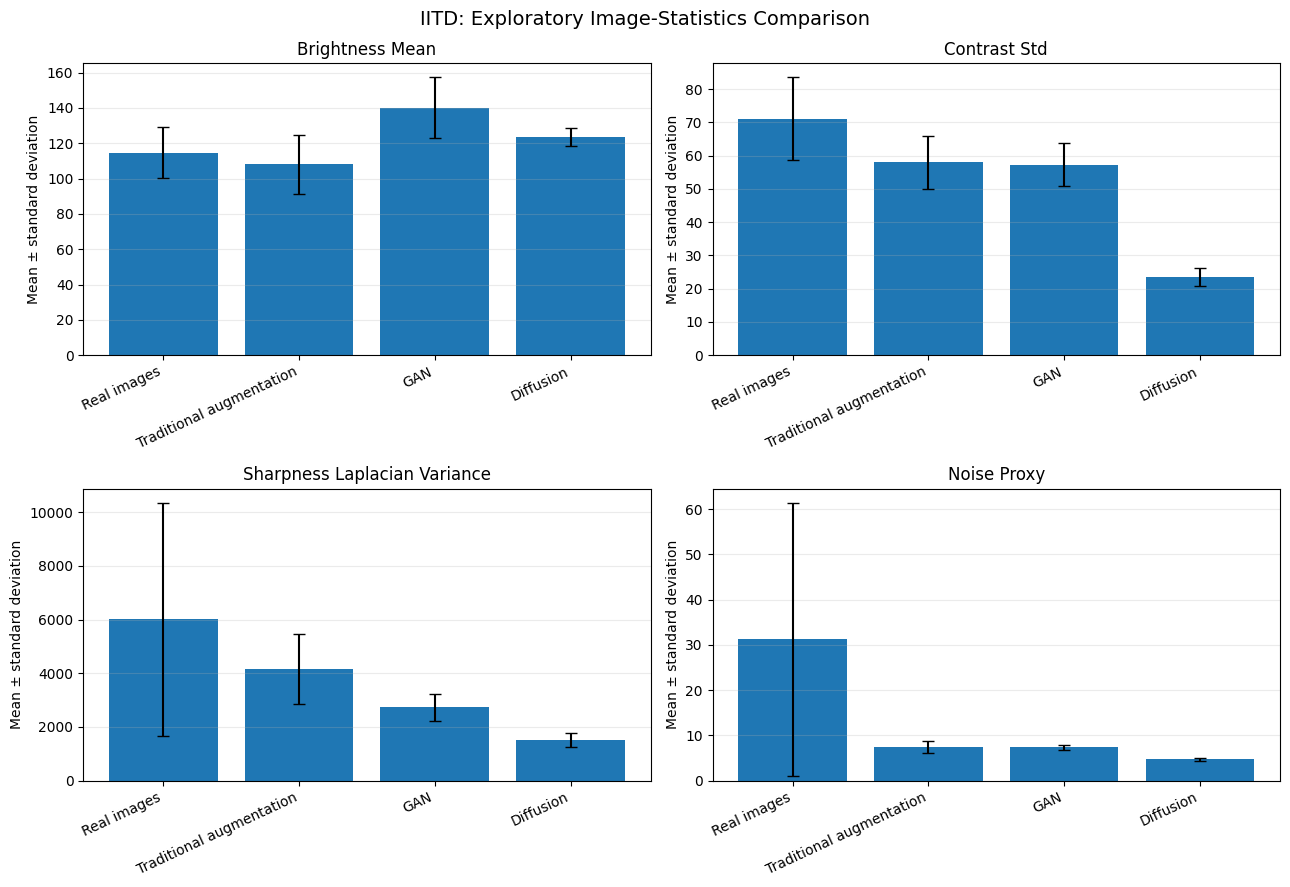

COMPARISON TABLE


,dataset,sample_count,metric,mean,std
0,Real images,3270,brightness_mean,114.700,14.540
1,Real images,3270,contrast_std,71.103,12.499
2,Real images,3270,sharpness_laplacian_variance,6017.498,4335.969
3,Real images,3270,noise_proxy,31.204,30.206
4,Traditional augmentation,100,brightness_mean,108.151,16.628
5,Traditional augmentation,100,contrast_std,58.037,7.967
6,Traditional augmentation,100,sharpness_laplacian_variance,4149.395,1302.011
7,Traditional augmentation,100,noise_proxy,7.391,1.298
8,GAN,100,brightness_mean,140.237,17.169
9,GAN,100,contrast_std,57.312,6.493



SAVED OUTPUTS
IITD_GAN_vs_Diffusion_metric_comparison.csv: True | 1,168 bytes
IITD_GAN_vs_Diffusion_summary.json: True | 2,674 bytes
IITD_GAN_vs_Diffusion_metric_comparison.png: True | 146,966 bytes

Sample counts:
Real images: 3270
Traditional augmentation: 100
GAN: 100
Diffusion: 16

Note: Higher brightness, contrast, sharpness, or noise values do not automatically mean better images.


In [4]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load existing metrics
# --------------------------------------------------
real_df = pd.read_csv(QUALITY_DIR / "IITD_quality_diversity_all_metrics.csv")
gan_df = pd.read_csv(QUALITY_DIR / "IITD_GAN_sample_quality_metrics.csv")
diff_df = pd.read_csv(QUALITY_DIR / "IITD_diffusion_sample_quality_metrics.csv")
trad_df = pd.read_csv(QUALITY_DIR / "IITD_traditional_sample_quality_metrics.csv")

metric_cols = [
    "brightness_mean",
    "contrast_std",
    "sharpness_laplacian_variance",
    "noise_proxy",
]

# Use real images only from the combined file
real_df = real_df[real_df["source"].astype(str).str.lower() == "real"].copy()

datasets = {
    "Real images": real_df,
    "Traditional augmentation": trad_df,
    "GAN": gan_df,
    "Diffusion": diff_df,
}

# --------------------------------------------------
# 2. Calculate descriptive statistics
# --------------------------------------------------
rows = []
summary = {
    "comparison_type": "Exploratory descriptive image-statistics comparison",
    "identity_preservation_verified": False,
    "metrics": metric_cols,
    "datasets": {},
    "limitations": [
        "GAN and traditional metrics use 100 sampled images each; diffusion uses 16 tiles.",
        "Metrics are low-level image statistics and do not establish biometric identity preservation.",
        "Different sample sizes make this an exploratory rather than definitive comparison.",
        "Noise proxy is an exploratory statistic, not a validated perceptual-quality metric.",
        "GAN and diffusion training configurations differ, so this is not a controlled architecture benchmark."
    ]
}

for name, df in datasets.items():
    stats = {"sample_count": int(len(df))}
    for metric in metric_cols:
        values = pd.to_numeric(df[metric], errors="coerce").dropna()
        stats[metric] = {
            "mean": float(values.mean()) if len(values) else None,
            "std": float(values.std()) if len(values) > 1 else None,
        }
        rows.append({
            "dataset": name,
            "sample_count": int(len(values)),
            "metric": metric,
            "mean": stats[metric]["mean"],
            "std": stats[metric]["std"],
        })
    summary["datasets"][name] = stats

comparison_df = pd.DataFrame(rows)
csv_path = OUT_DIR / "IITD_GAN_vs_Diffusion_metric_comparison.csv"
comparison_df.to_csv(csv_path, index=False)

json_path = OUT_DIR / "IITD_GAN_vs_Diffusion_summary.json"
with open(json_path, "w") as f:
    json.dump(summary, f, indent=2)

# --------------------------------------------------
# 3. Create a four-panel metric comparison chart
# --------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.ravel()

for ax, metric in zip(axes, metric_cols):
    labels = []
    means = []
    stds = []

    for name, df in datasets.items():
        values = pd.to_numeric(df[metric], errors="coerce").dropna()
        if len(values):
            labels.append(name)
            means.append(values.mean())
            stds.append(values.std() if len(values) > 1 else 0)

    ax.bar(range(len(labels)), means, yerr=stds, capsize=4)
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=25, ha="right")
    ax.set_ylabel("Mean ± standard deviation")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("IITD: Exploratory Image-Statistics Comparison", fontsize=14)
fig.tight_layout()

plot_path = OUT_DIR / "IITD_GAN_vs_Diffusion_metric_comparison.png"
fig.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# --------------------------------------------------
# 4. Print results and confirm saved files
# --------------------------------------------------
print("COMPARISON TABLE")
display(comparison_df.round(3))

print("\nSAVED OUTPUTS")
for path in [csv_path, json_path, plot_path]:
    print(f"{path.name}: {path.exists()} | {path.stat().st_size:,} bytes")

print("\nSample counts:")
for name, df in datasets.items():
    print(f"{name}: {len(df)}")

print("\nNote: Higher brightness, contrast, sharpness, or noise values do not automatically mean better images.")


In [5]:

import json

required_files = [
    OUT_DIR / "IITD_GAN_vs_Diffusion_metric_comparison.csv",
    OUT_DIR / "IITD_GAN_vs_Diffusion_summary.json",
    OUT_DIR / "IITD_GAN_vs_Diffusion_metric_comparison.png",
]

print("NOTEBOOK 11 OUTPUT VERIFICATION")
all_ok = True

for path in required_files:
    exists = path.is_file()
    all_ok = all_ok and exists
    print(f"{'OK' if exists else 'MISSING'}: {path.name}")

if all_ok:
    with open(required_files[1], "r") as f:
        saved_summary = json.load(f)

    print("\nSummary JSON: valid")
    print("Identity preservation verified:",
          saved_summary["identity_preservation_verified"])
    print("\nNotebook 11 outputs are ready.")
else:
    print("\nSome output files are missing; check the earlier cells.")


NOTEBOOK 11 OUTPUT VERIFICATION
OK: IITD_GAN_vs_Diffusion_metric_comparison.csv
OK: IITD_GAN_vs_Diffusion_summary.json
OK: IITD_GAN_vs_Diffusion_metric_comparison.png

Summary JSON: valid
Identity preservation verified: False

Notebook 11 outputs are ready.



# 11. GAN vs Diffusion: Comparison and Conclusion

## Objective

This experiment compares the existing GAN and diffusion-based synthetic ocular image generation pipelines using training information and exploratory image-level quality statistics from the IITD dataset.

## Experimental Summary

- **GAN:** Exploratory conditional DCGAN trained for 15 epochs at 64×64 resolution.
- **Diffusion:** Unconditional DDPM trained for 100 epochs at 64×64 resolution, with a reported training duration of approximately 321.81 seconds.
- **Evaluation:** 100 GAN samples and 16 diffusion tiles were evaluated using brightness, contrast, Laplacian sharpness, and an exploratory noise proxy.
- **Reference dataset:** 3,270 real images were available in the quality-assessment dataset.

## Observations

1. The mean brightness of GAN samples was 140.24, compared with 123.60 for diffusion samples and 114.70 for real images.
2. Mean contrast was 57.31 for GAN samples and 23.50 for diffusion samples, compared with 71.10 for real images.
3. Mean Laplacian sharpness was 2,738.36 for GAN samples and 1,501.30 for diffusion samples, compared with 6,017.50 for real images.
4. The exploratory noise proxy was 7.35 for GAN samples and 4.73 for diffusion samples, compared with 31.20 for real images.

## Interpretation

The measured statistics indicate differences between the real and generated image distributions. In particular, the generated samples have lower mean Laplacian sharpness than the real-image reference. The diffusion samples also show lower mean contrast in this evaluation.

These statistics do not, by themselves, establish visual realism, diversity, identity preservation, or usefulness for biometric recognition. The noise proxy is exploratory and should not be interpreted as a validated quality score.

## Limitations

- The sample counts are unequal: 100 GAN samples versus 16 diffusion tiles.
- The models use different training procedures and epoch counts; this is not a controlled architecture comparison.
- The diffusion model is unconditional and does not provide identity labels for generated samples.
- Conditional GAN labels do not establish that generated images preserve the corresponding subject's identity.
- The image-level metrics are not a substitute for visual inspection, distribution-level evaluation, or biometric recognition experiments.
- The existing quality-assessment pipeline uses different sample sources and does not establish that all preprocessing and evaluation conditions are fully equivalent.

## Conclusion

This experiment provides a preliminary descriptive comparison of GAN- and diffusion-generated ocular images. The measured statistics differ from those of real images, and the current evidence is insufficient to conclude that either generator is superior overall.

Identity preservation and biometric usefulness remain unverified. These results should therefore be treated as exploratory evidence rather than proof that synthetic augmentation improves ocular recognition.

## Output Files

The comparison notebook saves:

- `IITD_GAN_vs_Diffusion_metric_comparison.csv`
- `IITD_GAN_vs_Diffusion_summary.json`
- `IITD_GAN_vs_Diffusion_metric_comparison.png`

Output directory:

`results/IITD/notebook11_gan_vs_diffusion/`
